# Day 18 | Run a Language Model With Ollama

**KGP Talkie**

Install the runner, download a model, and send a first local request.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

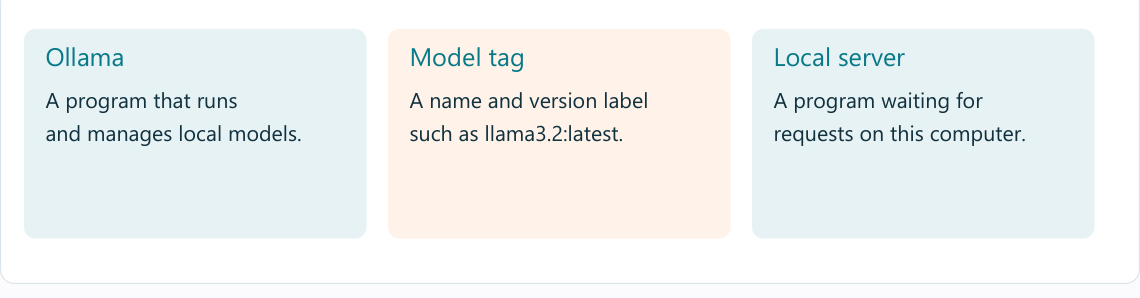

## Terminal setup

Open Ollama on Windows. In a terminal, run `ollama list`. If needed, run `ollama pull llama3.2`, then `ollama run llama3.2`. `pull` downloads the model; `run` starts a chat. The Python cells below use the same local server.

requests sends an HTTP request: a message from Python to a server.

In [4]:
import requests

In [5]:
url = "http://localhost:11434"

In [6]:
installed = requests.get(url + "/api/tags", timeout=10).json()

The list shows model names. Copy a chat tag from your own list.

In [7]:
[item["name"] for item in installed["models"]]

['nomic-embed-text:latest',
 'uncensored_1:latest',
 'uncensored:latest',
 'cooper:latest',
 'sheldon:latest',
 'llama3.2:latest',
 'qwen2.5:0.5b-small-my-model-copy',
 'qwen2.5:0.5b']

In [8]:
model = os.getenv("KGP_MODEL", "llama3.2")

A dictionary becomes JSON in the request. stream=False returns one complete result for our first check.

In [9]:
payload = {"model": model, "messages": [{"role": "user", "content": "Explain Python in one sentence."}], "stream": False}

In [10]:
response = requests.post(url + "/api/chat", json=payload, timeout=180)

Stop if the server reports a failed HTTP request rather than reading it as a success.

In [11]:
response.raise_for_status()

In [12]:
print(response.json()["message"]["content"])

Python is a high-level, versatile programming language that allows developers to write clear, concise code for various tasks, including web development, data analysis, machine learning, and more.


Change one question in the same request shape.

In [13]:
payload["messages"][0]["content"] = "Explain a Jupyter notebook in one sentence."

In [14]:
fresh = requests.post(url + "/api/chat", json=payload, timeout=180)
fresh.raise_for_status()

In [15]:
print(fresh.json()["message"]["content"])

A Jupyter Notebook is an interactive web-based environment that allows users to create and share documents containing live code, equations, visualizations, and narrative text in a format that can be easily shared, edited, and collaborated on.


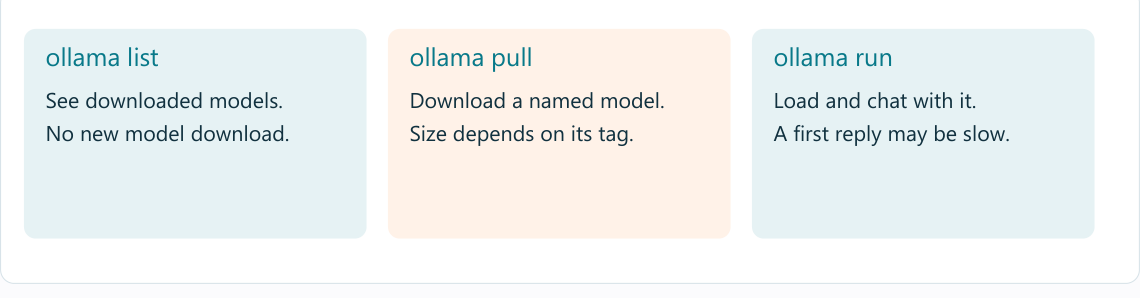

## Try a fresh input

Check the local chat endpoint in Python. localhost:11434 points to this computer, not a public website.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/ollama-setup-guide).